# Smart Support-Ticket Triage with NLP

**The business problem.** Support teams receive thousands of tickets. Someone has to read each one and decide
(1) which team should handle it and (2) how urgent it is. That manual triage is slow, inconsistent, and delays fixes.

**What this project does.** It trains machine learning models that read a ticket's text and:
1. **Route it** to the right support queue (Technical Support, Billing, IT Support, ...).
2. **Flag its priority** (low / medium / high).
3. **Know when it is unsure.** Confident predictions are routed automatically; uncertain ones go to a human.

**Workflow:** load data → clean text → explore (EDA) → baseline → TF-IDF model → transformer embedding model →
pick the best → confidence-based routing → business impact → priority model → try it on your own ticket.

> **How to run:** press **Run All** at the top of this notebook. Each step explains what it does and why.

## Step 1 — Settings and imports
Everything you might want to change lives in the settings cell, so you never have to dig through the code.

In [1]:
# ===== SETTINGS (safe to change) =====
RANDOM_STATE = 42          # makes results repeatable
TEST_SIZE = 0.2            # 20% of tickets are held back to test the model
TARGET_ACCURACY = 0.90     # accuracy we want on tickets that are routed automatically
TFIDF_C_OPTIONS = [1, 5, 20, 50, 100]   # values of C tried for the TF-IDF model; the best is picked in Step 7
USE_EMBEDDINGS = True      # set to False to skip the transformer model (faster)
EMBEDDING_MODEL = "all-MiniLM-L6-v2"   # small, fast sentence-transformer model

# Business assumptions for the impact estimate (change to fit the company)
TICKETS_PER_MONTH = 10_000
MINUTES_PER_MANUAL_TRIAGE = 3

In [2]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
Path("data").mkdir(exist_ok=True)
Path("images").mkdir(exist_ok=True)   # charts are saved here for your README / GitHub
print("Ready")

Ready


## Step 2 — Load the data
We use the public **Customer Support Tickets** dataset by Tobias Bueck (Hugging Face / Kaggle).
Each row is one support email with its subject, body, the queue it was routed to, and its priority.
The tickets are synthetic (generated to look realistic), which is normal for public support data, since real tickets are confidential.

The first run downloads the data and saves a copy to `data/tickets.csv`; later runs read that copy.
If the download fails, download any CSV from
[Kaggle: Customer IT Support – Ticket Dataset](https://www.kaggle.com/datasets/tobiasbueck/multilingual-customer-support-tickets),
rename it to `tickets.csv` and put it in the `data` folder.

In [3]:
LOCAL_FILE = Path("data/tickets.csv")
REQUIRED = {"subject", "body", "queue", "priority"}

def download_tickets():
    """Try the Hugging Face dataset; return a DataFrame or None."""
    try:
        from datasets import load_dataset
        ds = load_dataset("Tobi-Bueck/customer-support-tickets", split="train")
        return ds.to_pandas()
    except Exception as e:
        print("load_dataset did not work, trying the CSV files directly:", str(e)[:120])
    try:
        from huggingface_hub import list_repo_files, hf_hub_download
        repo = "Tobi-Bueck/customer-support-tickets"
        files = [f for f in list_repo_files(repo, repo_type="dataset") if f.endswith(".csv")]
        best = None
        for f in files:
            df = pd.read_csv(hf_hub_download(repo, f, repo_type="dataset"))
            df.columns = [c.lower() for c in df.columns]
            if REQUIRED.issubset(df.columns) and (best is None or len(df) > len(best)):
                best = df
        return best
    except Exception as e:
        print("Direct download failed:", str(e)[:120])
        return None

if LOCAL_FILE.exists():
    raw = pd.read_csv(LOCAL_FILE)
else:
    raw = download_tickets()
    if raw is None:
        raise SystemExit("Could not download the data. See the note above to download it manually.")
    raw.to_csv(LOCAL_FILE, index=False)

raw.columns = [c.lower() for c in raw.columns]
print(f"{len(raw):,} tickets, {raw.shape[1]} columns")
raw.head(3)

61,765 tickets, 16 columns


,subject,body,answer,type,queue,priority,language,version,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6,tag_7,tag_8
0,Wesentlicher Sicherheitsvorfall,"Sehr geehrtes Support-Team,\n\nich möchte einen gravierenden Sicherheitsvorfall melden, der gegenwärtig mehrere Komp...",Vielen Dank für die Meldung des kritischen Sicherheitsvorfalls und die Bereitstellung der Übersicht über die betroff...,Incident,Technical Support,high,de,51.0,Security,Outage,Disruption,Data Breach,NaN,NaN,NaN,NaN
1,Account Disruption,"Dear Customer Support Team,\n\nI am writing to report a significant problem with the centralized account management ...","Thank you for reaching out, <name>. We are aware of the outage affecting the centralized account management system, ...",Incident,Technical Support,high,en,51.0,Account,Disruption,Outage,IT,Tech Support,NaN,NaN,NaN
2,Query About Smart Home System Integration Features,"Dear Customer Support Team,\n\nI hope this message reaches you well. I am reaching out to request detailed informati...","Thank you for your inquiry. Our products support integration with Amazon Alexa, Google Assistant, and Apple HomeKit....",Request,Returns and Exchanges,medium,en,51.0,Product,Feature,Tech Support,NaN,NaN,NaN,NaN,NaN


## Step 3 — Clean the data
* Keep English tickets only (the dataset also has German and other languages).
* Join the subject and body into one `text` field, since both carry meaning.
* Drop empty or duplicate tickets.
* Make the priority labels consistent (lower case).
* Drop queues or priorities with fewer than 30 tickets (too few to learn from).

In [4]:
df = raw.copy()
if "language" in df.columns:
    df = df[df["language"].astype(str).str.lower().str.startswith("en")]
print(f"English tickets: {len(df):,}")

df["subject"] = df["subject"].fillna("")
df["body"] = df["body"].fillna("")
df["text"] = (df["subject"] + ". " + df["body"]).str.replace(r"\s+", " ", regex=True).str.strip()
df["priority"] = df["priority"].astype(str).str.lower().str.strip()

def drop_step(new_df, reason):
    """Apply one cleaning step and report how many tickets it removed."""
    print(f"  - {reason}: {len(df) - len(new_df):,} removed")
    return new_df

df = drop_step(df[df["text"].str.len() > 20], "too short (20 characters or less)")
df = drop_step(df.dropna(subset=["queue"]), "missing queue")
df = drop_step(df.drop_duplicates(subset="text"), "exact duplicates (same subject + body)")
df = df[["text", "queue", "priority"]]

# Drop very rare labels: a model can't learn a queue from a handful of examples
MIN_TICKETS = 30
df = drop_step(df[df["queue"].map(df["queue"].value_counts()) >= MIN_TICKETS], f"queue with < {MIN_TICKETS} tickets")
df = drop_step(df[df["priority"].map(df["priority"].value_counts()) >= MIN_TICKETS], f"priority with < {MIN_TICKETS} tickets")
df = df.reset_index(drop=True)

print(f"Clean English tickets: {len(df):,}")
print(f"Queues: {df['queue'].nunique()} | Priorities: {sorted(df['priority'].unique())}")

English tickets: 28,261


  - too short (20 characters or less): 5 removed
  - missing queue: 0 removed
  - exact duplicates (same subject + body): 4,512 removed
  - queue with < 30 tickets: 0 removed
  - priority with < 30 tickets: 0 removed
Clean English tickets: 23,744
Queues: 10 | Priorities: ['high', 'low', 'medium']


**Observations**
* Almost all of the removed tickets are **exact duplicates**. Each one appears exactly twice in the dataset, once tagged `version 400` and once with no version, so the same tickets were included twice when the dataset was put together. Both copies always have the same queue and priority, so keeping one loses nothing.
* Removing them matters: otherwise one copy could land in the training set and the other in the test set, and the model would be graded on tickets it had already seen, making the scores look better than they really are.
* The few very short tickets (*"Help"*, *"Support needed"*, *"Can you assist me?"*) carry nothing to classify.
* No queue or priority was too rare to keep: every one has at least 30 English tickets.

## Step 4 — Explore the data (EDA)
Before modeling, we check three things:
1. **How many tickets each queue gets.** If some queues are rare, plain accuracy can be misleading.
2. **How priorities are spread.**
3. **Which words are typical for each queue.** This tells us whether the text actually contains a routing signal.

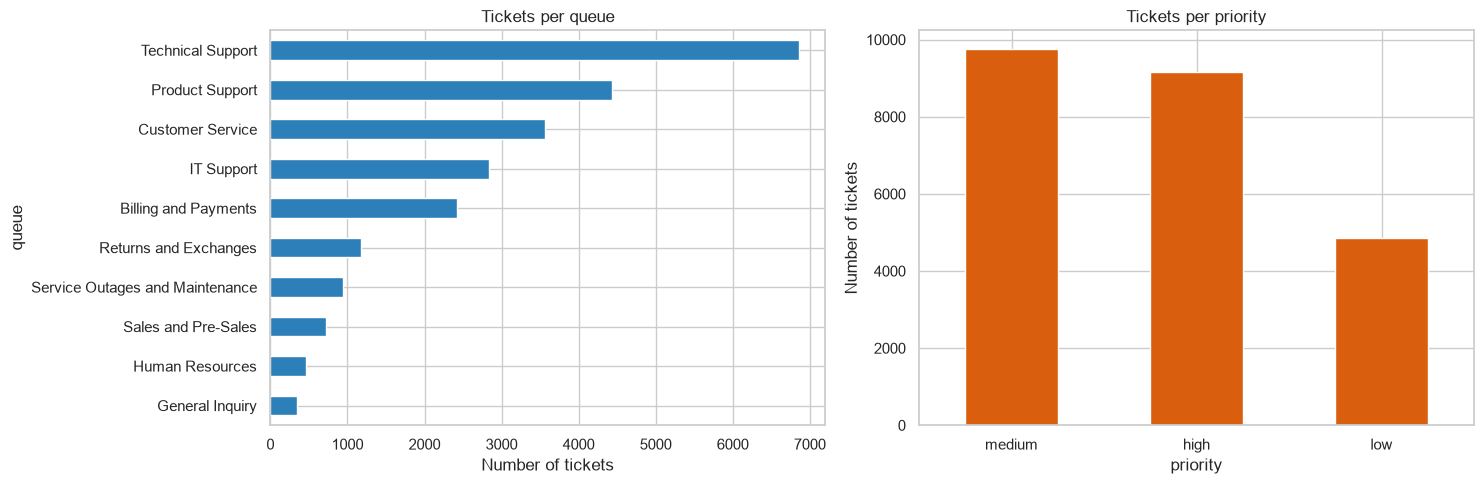

Median words per ticket: 60


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
df["queue"].value_counts().sort_values().plot(kind="barh", ax=axes[0], color="#2c7fb8")
axes[0].set_title("Tickets per queue"); axes[0].set_xlabel("Number of tickets")
df["priority"].value_counts().plot(kind="bar", ax=axes[1], color="#d95f0e", rot=0)
axes[1].set_title("Tickets per priority"); axes[1].set_ylabel("Number of tickets")
plt.tight_layout(); plt.savefig("images/eda_distribution.png", dpi=120); plt.show()

df["words"] = df["text"].str.split().str.len()
print("Median words per ticket:", int(df["words"].median()))

**Observations**
* The raw download has 61,765 tickets: 33,504 German and 28,261 English. After keeping English tickets and cleaning, **23,744 tickets in 10 queues** remain.
* Queue sizes are very uneven. **Technical Support** has 6,858 tickets (29%), while **General Inquiry** has only 342 (1.4%), about 20 times fewer. That is why we report macro F1 and use balanced class weights.
* Priorities are more balanced: medium 9,750 (41%), high 9,149 (39%), low 4,845 (20%).
* A typical ticket is short: the median is **60 words**.

In [6]:
# Top 8 most distinctive words per queue (TF-IDF scores averaged within each queue)
tfidf_eda = TfidfVectorizer(stop_words="english", max_features=5000, min_df=3)
X_eda = tfidf_eda.fit_transform(df["text"])
vocab = np.array(tfidf_eda.get_feature_names_out())

top_words = {}
for q in df["queue"].value_counts().index:
    mean_scores = np.asarray(X_eda[(df["queue"] == q).values].mean(axis=0)).ravel()
    top_words[q] = ", ".join(vocab[mean_scores.argsort()[::-1][:8]])
pd.DataFrame.from_dict(top_words, orient="index", columns=["Most typical words"])

,Most typical words
Technical Support,"data, issue, software, problem, security, analytics, medical, support"
Product Support,"data, issue, security, analytics, integration, investment, medical, digital"
Customer Service,"data, investment, analytics, medical, strategies, digital, integration, security"
IT Support,"data, software, issue, problem, tools, analytics, security, support"
Billing and Payments,"billing, payment, information, data, services, details, support, provide"
Returns and Exchanges,"data, investment, security, medical, analytics, software, digital, information"
Service Outages and Maintenance,"service, outage, outages, data, impacting, network, tools, issue"
Sales and Pre-Sales,"data, information, analytics, investment, strategies, digital, brand, integration"
Human Resources,"data, security, employee, software, access, issue, support, information"
General Inquiry,"data, investment, digital, medical, analytics, security, engagement, strategies"


**Observations**
* Only a few queues have clearly distinctive words: **Billing and Payments** (*billing, payment*), **Service Outages and Maintenance** (*service, outage, impacting, network*) and **Human Resources** (*employee, access*).
* Most other queues share the same generic words (*data, analytics, security, investment, medical*). Those words describe the customer's industry, not the type of problem.
* So we can expect Billing and Service Outages to be easy to route, and the overlapping support queues (Technical, Product, IT, Customer Service) to be harder.

## Step 5 — Split into training and test sets
The model learns from 80% of the tickets and is graded on the other 20%, which it has never seen.
`stratify` keeps the same queue mix in both parts.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["queue"], test_size=TEST_SIZE, stratify=df["queue"], random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} tickets | Test: {len(X_test):,} tickets")

results = {}   # we store every model's scores here to compare them later

def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="macro")
    results[name] = {"Accuracy": round(acc, 3), "Macro F1": round(f1, 3)}
    print(f"{name}: accuracy {acc:.1%} | macro F1 {f1:.3f}")

Train: 18,995 tickets | Test: 4,749 tickets


## Step 6 — Baseline: always guess the biggest queue
A baseline tells us what "no intelligence" scores. Any real model must beat it clearly.

**Macro F1** averages the score of every queue equally, so a model can't look good by only getting the big queues right.

In [8]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
evaluate("Baseline (most frequent queue)", y_test, baseline.predict(X_test))

Baseline (most frequent queue): accuracy 28.9% | macro F1 0.045


## Step 7 — Model 1: TF-IDF + Logistic Regression
**TF-IDF** turns each ticket into numbers: words that are frequent in this ticket but rare overall get high scores.
We use single words and two-word phrases (e.g. "password reset").
**Logistic Regression** then learns which words point to which queue.
`class_weight="balanced"` makes the model pay equal attention to small queues.

`C` controls how closely the model fits the training tickets (higher = less regularisation).
We pick it with 3-fold cross-validation **on the training set only**, so the test set stays untouched.

In [9]:
def make_tfidf_model(C):
    return make_pipeline(
        TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=50_000),
        LogisticRegression(max_iter=2000, C=C, class_weight="balanced"))

# Choose C with 3-fold cross-validation on the training set (takes a minute or two)
cv_scores = {}
for C in TFIDF_C_OPTIONS:
    cv_scores[C] = cross_val_score(make_tfidf_model(C), X_train, y_train, cv=3, scoring="f1_macro", n_jobs=-1).mean()
    print(f"C = {C:>3}: cross-validated macro F1 {cv_scores[C]:.3f}")
best_C = max(cv_scores, key=cv_scores.get)
print(f"Using C = {best_C}\n")

tfidf_model = make_tfidf_model(best_C).fit(X_train, y_train)
evaluate("TF-IDF + Logistic Regression", y_test, tfidf_model.predict(X_test))

C =   1: cross-validated macro F1 0.485


C =   5: cross-validated macro F1 0.575


C =  20: cross-validated macro F1 0.606


C =  50: cross-validated macro F1 0.610


C = 100: cross-validated macro F1 0.609
Using C = 50



TF-IDF + Logistic Regression: accuracy 66.7% | macro F1 0.663


## Step 8 — Model 2: Transformer sentence embeddings + Logistic Regression
TF-IDF only matches exact words. A **sentence-transformer** (a small pretrained transformer model) turns each ticket
into a vector that captures *meaning*, so "can't log in" and "authentication fails" end up close together.
We then train the same Logistic Regression on those vectors.

The first run downloads the model (about 90 MB) and takes a few minutes to encode all tickets.

In [10]:
embed_model = None
if USE_EMBEDDINGS:
    try:
        from sentence_transformers import SentenceTransformer
        encoder = SentenceTransformer(EMBEDDING_MODEL)
        E_train = encoder.encode(X_train.tolist(), batch_size=64, show_progress_bar=True, normalize_embeddings=True)
        E_test = encoder.encode(X_test.tolist(), batch_size=64, show_progress_bar=True, normalize_embeddings=True)
        embed_model = LogisticRegression(max_iter=3000, C=10, class_weight="balanced").fit(E_train, y_train)
        evaluate("Sentence embeddings + Logistic Regression", y_test, embed_model.predict(E_test))
    except ImportError:
        print("sentence-transformers is not installed. Run: pip install sentence-transformers")
else:
    print("Skipped (USE_EMBEDDINGS = False)")

W1117 11:18:34.960000 66026 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 10385.19it/s]

Batches:   0%|          | 0/297 [00:00<?, ?it/s]

Batches:   0%|          | 1/297 [00:00<04:29,  1.10it/s]

Batches:   1%|          | 2/297 [00:01<02:35,  1.90it/s]

... (248 outputs left out)

Batches:  93%|█████████▎| 70/75 [00:06<00:00, 23.13it/s]

Batches:  99%|█████████▊| 74/75 [00:06<00:00, 27.06it/s]

Batches: 100%|██████████| 75/75 [00:06<00:00, 11.08it/s]

Sentence embeddings + Logistic Regression: accuracy 29.5% | macro F1 0.282


## Step 9 — Compare the models and pick the best

In [11]:
comparison = pd.DataFrame(results).T.sort_values("Macro F1", ascending=False)
display(comparison)

model_names = [m for m in comparison.index if not m.startswith("Baseline")]
best_name = model_names[0]
if best_name.startswith("Sentence"):
    best_proba = embed_model.predict_proba(E_test); classes = embed_model.classes_
else:
    best_proba = tfidf_model.predict_proba(X_test); classes = tfidf_model.classes_
best_pred = classes[best_proba.argmax(axis=1)]
print("Best model:", best_name)
print(classification_report(y_test, best_pred, digits=3))

,Accuracy,Macro F1
TF-IDF + Logistic Regression,0.667,0.663
Sentence embeddings + Logistic Regression,0.295,0.282
Baseline (most frequent queue),0.289,0.045


Best model: TF-IDF + Logistic Regression
                                 precision    recall  f1-score   support

           Billing and Payments      0.858     0.849     0.853       483
               Customer Service      0.611     0.643     0.627       714
                General Inquiry      0.800     0.412     0.544        68
                Human Resources      0.881     0.641     0.742        92
                     IT Support      0.602     0.593     0.597       567
                Product Support      0.601     0.609     0.605       886
          Returns and Exchanges      0.687     0.626     0.655       235
            Sales and Pre-Sales      0.630     0.600     0.615       145
Service Outages and Maintenance      0.745     0.658     0.699       187
              Technical Support      0.678     0.714     0.696      1372

                       accuracy                          0.667      4749
                      macro avg      0.709     0.634     0.663      4749
        

**Observations**
* **TF-IDF + Logistic Regression is the best model:** 66.7% accuracy and 0.663 macro F1, compared with 28.9% accuracy and 0.045 macro F1 for the baseline. That is more than twice as accurate across 10 queues.
* Tuning `C` in Step 7 mattered. The original setting (C = 5) scored 61.8% accuracy. Cross-validation picked C = 50, which gains about 5 points.
* **Sentence embeddings did surprisingly poorly** (29.5% accuracy, 0.282 macro F1), barely above the baseline on accuracy. Its macro F1 is still much higher than the baseline's (0.282 vs 0.045), so it does learn something about every queue.
  * **This is not a bug. The embeddings just don't carry the routing signal.** Even on its own *training* tickets this model reaches only about 35% accuracy, compared with over 95% for TF-IDF. Trying other settings (C = 1 to 100, with or without balanced weights) never got it above 42% accuracy or 0.33 macro F1.
  * The reason: a general-purpose embedding summarises what a ticket is *about* (its industry and topic), and Step 4 showed those topics are shared across queues. TF-IDF can use the specific words that do separate queues (*invoice*, *outage*, *employee*, *firmware*). Fine-tuning the transformer on the tickets, instead of using it frozen, would be the next thing to try.
* Per queue, **Billing and Payments** is easiest (F1 0.85). **General Inquiry** is hardest (F1 0.54): it is precise (80%) but finds only 41% of its tickets, because it is the smallest queue.

## Step 10 — Where does the model get confused?
The **confusion matrix** shows, for each true queue (rows), where its tickets were sent (columns).
Values are row percentages; the diagonal is "routed correctly".
Mix-ups between similar teams (for example Technical Support vs Product Support) are expected and useful to explain in an interview.

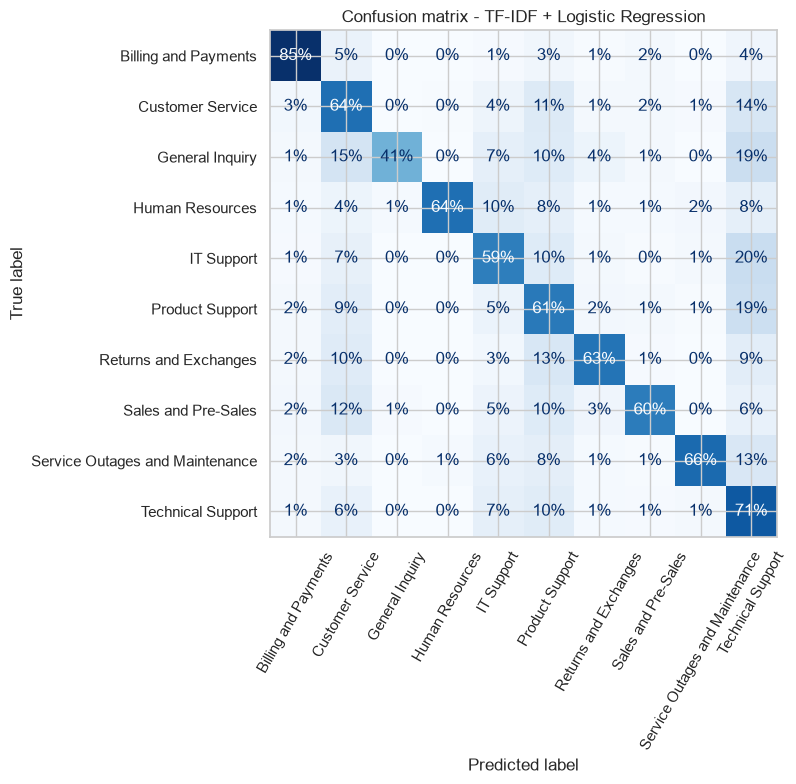

In [12]:
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, normalize="true", values_format=".0%",
                                        cmap="Blues", ax=ax, xticks_rotation=60, colorbar=False)
ax.set_title(f"Confusion matrix - {best_name}")
plt.tight_layout(); plt.savefig("images/confusion_matrix.png", dpi=120); plt.show()

**Observations**
* **Technical Support works as a catch-all.** Many tickets from other queues are sent there: 20% of IT Support, 19% of Product Support, 19% of General Inquiry, 14% of Customer Service and 13% of Service Outages tickets.
* **Product Support** is the second most common wrong destination: about 10% of tickets from most other queues end up there.
* **Billing and Payments is routed correctly 85% of the time** and Technical Support 71%, which matches the distinctive vocabulary seen in Step 4.
* In practice, many of these mix-ups are between teams that do similar work. A merged "support" queue, or a clear rule for who owns which issue, would remove much of the error.

## Step 11 — Route automatically only when the model is confident
In real support teams, a wrong route costs more than a short wait. So instead of routing every ticket,
we use the model's **confidence** (its highest predicted probability):

* confidence **above** a threshold → route automatically
* confidence **below** the threshold → send to a human

The chart shows the trade-off: a higher threshold means fewer tickets automated, but more of them correct.
We pick the lowest threshold that reaches the target accuracy set in Step 1.

To keep the test fair, the threshold is **chosen on a validation set** (20% of the training tickets, held out from a
temporary copy of the model) and then **checked on the test set**. Choosing it on the test set itself would
make the result look better than it would be on new tickets.

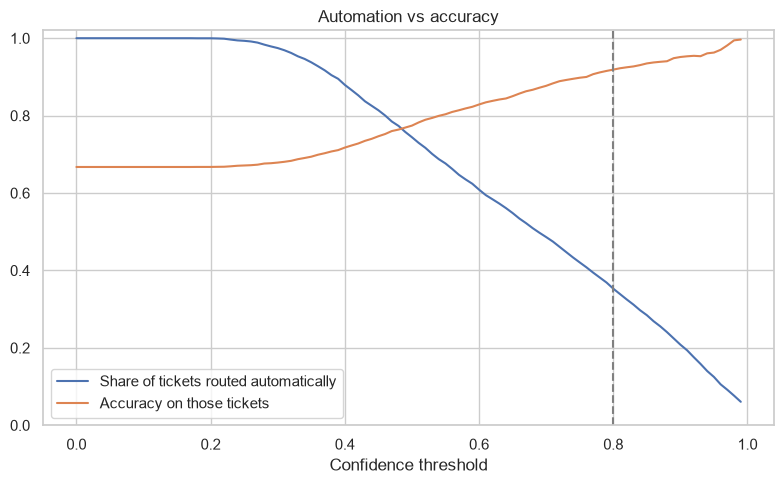

Threshold 0.80 (chosen on the validation set). On the test set: 35.3% of tickets routed automatically with 91.9% accuracy; the rest go to a human.


In [13]:
def threshold_curve(proba, labels, y_true):
    """For each threshold: share of tickets above it, and accuracy on those tickets."""
    confidence = proba.max(axis=1)
    correct = labels[proba.argmax(axis=1)] == np.asarray(y_true)
    rows = []
    for t in np.arange(0.0, 1.0, 0.01):
        mask = confidence >= t
        if mask.sum() < 20:
            break
        rows.append({"threshold": t, "automated_share": mask.mean(), "accuracy_automated": correct[mask].mean()})
    return pd.DataFrame(rows)

# 1) Choose the threshold on a validation set carved out of the training data
fit_idx, val_idx = train_test_split(np.arange(len(X_train)), test_size=0.2,
                                    stratify=y_train, random_state=RANDOM_STATE)
if best_name.startswith("Sentence"):
    tmp = LogisticRegression(max_iter=3000, C=10, class_weight="balanced").fit(E_train[fit_idx], y_train.iloc[fit_idx])
    val_proba = tmp.predict_proba(E_train[val_idx])
else:
    tmp = make_tfidf_model(best_C).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
    val_proba = tmp.predict_proba(X_train.iloc[val_idx])
val_curve = threshold_curve(val_proba, tmp.classes_, y_train.iloc[val_idx])
meets = val_curve[val_curve["accuracy_automated"] >= TARGET_ACCURACY]
best_t = meets["threshold"].iloc[0] if len(meets) else val_curve.loc[val_curve["accuracy_automated"].idxmax(), "threshold"]

# 2) Check that threshold on the untouched test set
curve = threshold_curve(best_proba, classes, y_test)
chosen = curve.loc[(curve["threshold"] - best_t).abs().idxmin()]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(curve["threshold"], curve["automated_share"], label="Share of tickets routed automatically")
ax.plot(curve["threshold"], curve["accuracy_automated"], label="Accuracy on those tickets")
ax.axvline(chosen["threshold"], color="grey", linestyle="--")
ax.set_xlabel("Confidence threshold"); ax.set_ylim(0, 1.02); ax.legend(loc="lower left")
ax.set_title("Automation vs accuracy")
plt.tight_layout(); plt.savefig("images/confidence_routing.png", dpi=120); plt.show()

print(f"Threshold {chosen['threshold']:.2f} (chosen on the validation set). On the test set: "
      f"{chosen['automated_share']:.1%} of tickets routed automatically with {chosen['accuracy_automated']:.1%} accuracy; "
      f"the rest go to a human.")

**Observations**
* Routing every ticket gives 66.7% accuracy, which is too low to fully automate.
* The validation set picked a threshold of **0.80**. On the untouched test set this routes **35.3% of tickets** automatically with **91.9% accuracy**, meeting the 90% target. The other 65% go to a human.
* Because the threshold was chosen without looking at the test set, this result is a fair estimate of how it would perform on new tickets.
* The curve shows the trade-off: lowering the threshold to 0.6 would automate about 60% of tickets, but accuracy would drop to about 83%.

## Step 12 — Business impact
We translate the result into time saved, using the assumptions in Step 1.
Change those numbers to match any company's ticket volume.

In [14]:
auto_tickets = TICKETS_PER_MONTH * chosen["automated_share"]
hours_saved = auto_tickets * MINUTES_PER_MANUAL_TRIAGE / 60
print(f"Of {TICKETS_PER_MONTH:,} tickets a month, about {auto_tickets:,.0f} are routed automatically.")
print(f"That saves about {hours_saved:,.0f} hours of manual triage per month "
      f"(at {MINUTES_PER_MANUAL_TRIAGE} minutes per ticket).")

Of 10,000 tickets a month, about 3,529 are routed automatically.
That saves about 176 hours of manual triage per month (at 3 minutes per ticket).


**Observations**
* At 10,000 tickets a month, about **3,529 tickets** are routed automatically, saving about **176 hours** of manual triage per month (3 minutes each). That is roughly one full-time person.
* A better model would raise the automated share at the same 90% accuracy, so the savings grow directly with model quality.

## Step 13 — Bonus: predict priority and catch urgent tickets
The same approach can flag urgency. Here the most important number is **recall on high-priority tickets**:
out of all truly urgent tickets, how many did we catch? Missing an urgent ticket is the costly mistake.

In [15]:
Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    df["text"], df["priority"], test_size=TEST_SIZE, stratify=df["priority"], random_state=RANDOM_STATE)
priority_model = make_pipeline(
    TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    LogisticRegression(max_iter=2000, C=5, class_weight="balanced")).fit(Xp_train, yp_train)
yp_pred = priority_model.predict(Xp_test)
print(classification_report(yp_test, yp_pred, digits=3))

urgent_label = "critical" if "critical" in set(yp_test) else "high"
urgent_recall = ((yp_pred == urgent_label) & (yp_test.values == urgent_label)).sum() / max((yp_test.values == urgent_label).sum(), 1)
print(f"Recall on '{urgent_label}' tickets: {urgent_recall:.0%}")

              precision    recall  f1-score   support

        high      0.711     0.722     0.717      1830
         low      0.630     0.637     0.633       969
      medium      0.700     0.686     0.693      1950

    accuracy                          0.690      4749
   macro avg      0.681     0.682     0.681      4749
weighted avg      0.690     0.690     0.690      4749

Recall on 'high' tickets: 72%


**Observations**
* The priority model reaches **69.0% accuracy** (macro F1 0.681) across the three levels.
* It catches **72.2% of high-priority tickets**, and 71.1% of the tickets it flags as high really are high.
* About 28% of urgent tickets are still missed, so this model should help an agent prioritise rather than be the only safety net for urgent issues.

## Step 14 — Try it on your own ticket
Type any support message and see where the model would send it, how sure it is, and how urgent it looks.

In [16]:
def triage(ticket_text):
    if best_name.startswith("Sentence"):
        probs = embed_model.predict_proba(encoder.encode([ticket_text], normalize_embeddings=True))[0]
        labels = embed_model.classes_
    else:
        probs = tfidf_model.predict_proba([ticket_text])[0]
        labels = tfidf_model.classes_
    queue, conf = labels[probs.argmax()], probs.max()
    action = "route automatically" if conf >= chosen["threshold"] else "send to a human for review"
    priority = priority_model.predict([ticket_text])[0]
    print(f"Ticket: {ticket_text}")
    print(f"  Queue: {queue} (confidence {conf:.0%}) -> {action}")
    print(f"  Priority: {priority}\n")

triage("Our main database server went down after last night's update and nobody can access the CRM.")
triage("I was charged twice for my subscription this month, please refund the extra payment.")
triage("Could you tell me which plan includes priority support and how much it costs?")

Ticket: Our main database server went down after last night's update and nobody can access the CRM.
  Queue: Product Support (confidence 73%) -> send to a human for review
  Priority: high

Ticket: I was charged twice for my subscription this month, please refund the extra payment.
  Queue: Billing and Payments (confidence 100%) -> route automatically
  Priority: high

Ticket: Could you tell me which plan includes priority support and how much it costs?
  Queue: Returns and Exchanges (confidence 30%) -> send to a human for review
  Priority: medium



**Observations** (with TF-IDF, the best model)
* **Database outage** → Product Support with 73% confidence. That is below the 0.80 threshold, so it goes to a human; priority **high**. The urgency is right, but the queue is debatable (Service Outages and Maintenance or IT Support would fit better), which is exactly the kind of ticket that should get a human check.
* **Double charge** → Billing and Payments with **100%** confidence, so it is routed automatically; priority high. This is the clear-cut case the model handles best.
* **Pricing question** → Returns and Exchanges with only 30% confidence; priority medium. The queue is wrong (it should be Sales and Pre-Sales), but the low confidence sends it to a human. This shows why the confidence threshold matters.

## Step 15 — Save the results
This writes your key numbers to `results.json`. Copy them into your README and resume.

In [17]:
summary = {
    "tickets_used": int(len(df)),
    "queues": int(df["queue"].nunique()),
    "model_comparison": results,
    "best_model": best_name,
    "tfidf_C": best_C,
    "confidence_threshold": round(float(chosen["threshold"]), 2),
    "share_auto_routed": round(float(chosen["automated_share"]), 3),
    "accuracy_on_auto_routed": round(float(chosen["accuracy_automated"]), 3),
    "hours_saved_per_month": round(float(hours_saved)),
    "urgent_label": urgent_label,
    "urgent_recall": round(float(urgent_recall), 3),
}
Path("results.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "tickets_used": 23744,
  "queues": 10,
  "model_comparison": {
    "Baseline (most frequent queue)": {
      "Accuracy": 0.289,
      "Macro F1": 0.045
    },
    "TF-IDF + Logistic Regression": {
      "Accuracy": 0.667,
      "Macro F1": 0.663
    },
    "Sentence embeddings + Logistic Regression": {
      "Accuracy": 0.295,
      "Macro F1": 0.282
    }
  },
  "best_model": "TF-IDF + Logistic Regression",
  "tfidf_C": 50,
  "confidence_threshold": 0.8,
  "share_auto_routed": 0.353,
  "accuracy_on_auto_routed": 0.919,
  "hours_saved_per_month": 176,
  "urgent_label": "high",
  "urgent_recall": 0.722
}


## Conclusion
* The best model, **TF-IDF + Logistic Regression** (C = 50, chosen by cross-validation), routes tickets to **10** queues with **66.7%** accuracy and **0.663** macro F1,
  versus **28.9%** accuracy (0.045 macro F1) for always guessing the biggest queue. The frozen sentence-embedding model scored only 29.5%.
* With a confidence threshold of **0.80** (chosen on a validation set), **35.3%** of tickets can be routed automatically at **91.9%** accuracy on the test set,
  saving about **176 hours** of triage per month at 10,000 tickets.
* The priority model catches **72.2%** of high-priority tickets (69.0% overall priority accuracy).
* **Main limitation:** apart from Billing, Service Outages and HR, the queues share most of their vocabulary, and many errors go to Technical Support as a catch-all.
* **Next steps:** fine-tune a transformer on the tickets (the frozen embeddings underperformed), add the customer's product as a feature, and retrain monthly as new issue types appear.